<a href="https://colab.research.google.com/github/gautamkr1876/AIML_ClassNotes/blob/main/8.%20Agentic%20AI%20Systems/20.%20Advanced%20Diffusion%20%26%20Agentic%20Image%20Generation/L19_%20Advanced%20Diffusion.ipynb" target="_blank">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Conditioning & Customizing Diffusion Models
### Image-to-Image, Inpainting, ControlNet, IP-Adapter, and Teaching a Model New Concepts


---

## Agenda

By the end of this notebook, you will be able to:

1. Transform an existing image using **Image-to-Image** generation and control how much the model "listens" to the original image.
2. Selectively edit regions of an image using **Inpainting**, and extend an image beyond its borders using **Outpainting**.
3. Precisely control the *structure* of a generated image (pose, depth, edges, layout) using **ControlNet**.
4. Use a reference image instead of text to guide style and content using **IP-Adapter**.
5. Combine multiple structural constraints at once using **Multi-ControlNet**.
6. Teach a model a new, custom concept (a face, an object, a style) using **Textual Inversion**.
7. Fully personalize a model on a subject using **DreamBooth**.
8. Make an informed decision on **when to use LoRA vs Textual Inversion vs full fine-tuning**, based on your data, compute, and goal.



## Setup

Before we touch any of the eight techniques above, we need the same base toolkit for all of them: `diffusers`, `transformers`, `accelerate`, and a couple of helper libraries for extracting ControlNet conditioning maps later.

In [ ]:
!pip install -q diffusers transformers accelerate safetensors controlnet_aux peft torchvision
import torch
print("CUDA available:", torch.cuda.is_available())


CUDA available: True


---
## Section 1 — Image-to-Image Transformation

We start here because it is the smallest possible step away from plain text-to-image, and it introduces the one idea every later section reuses: **you don't have to start denoising from pure noise — you can start from a partially-noised real image instead.**

### The analogy
Think of text-to-image as sculpting from a raw, formless block of marble — the model starts from pure noise. **Image-to-image** is different: instead of starting from a raw block, you start from an *already-carved statue* and ask the sculptor to re-carve it based on new instructions. The **strength** parameter controls how much of the original statue survives — low strength = light touch-ups, high strength = almost a full re-carve.

Technically: instead of starting the reverse diffusion process from pure Gaussian noise at timestep T, we take our input image, partially noise it up to some intermediate timestep, and then run the denoising process from there. The less noise we add (lower `strength`), the closer the output stays to the input.


In [ ]:
import torch
from diffusers import AutoPipelineForImage2Image

pipe = AutoPipelineForImage2Image.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    dtype=torch.float16,  # replaces deprecated torch_dtype
)

# VAE memory options
pipe.vae.enable_tiling()
pipe.vae.enable_slicing()

# Optional; omit on PyTorch 2+ unless you need extra VRAM savings,
# since it may slow inference with SDPA.
# pipe.enable_attention_slicing()

# Requires CUDA + accelerate; don't call pipe.to("cuda") as well.
pipe.enable_model_cpu_offload()

[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

**Instructor note**:- Please upload a city image for the below code cell to work

**img link**:- https://drive.google.com/file/d/1OeFmGdFWJMouJ5U4R1U7qEo7qHcNeBhb/view?usp=sharing

Original image


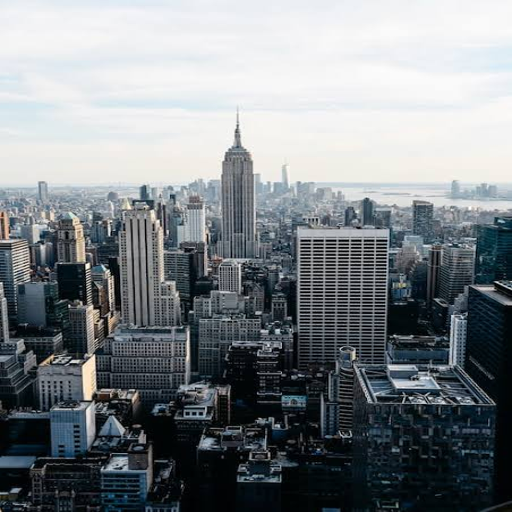

In [ ]:
from diffusers.utils import load_image
from IPython.display import display

init_image = load_image(
    "/content/city image.jpeg" #Update the path here
).resize((512, 512)) # SD 1.5's native resolution — keep it here for best quality/speed
print("Original image")
display(init_image)

  0%|          | 0/6 [00:00<?, ?it/s]

strength=0.2


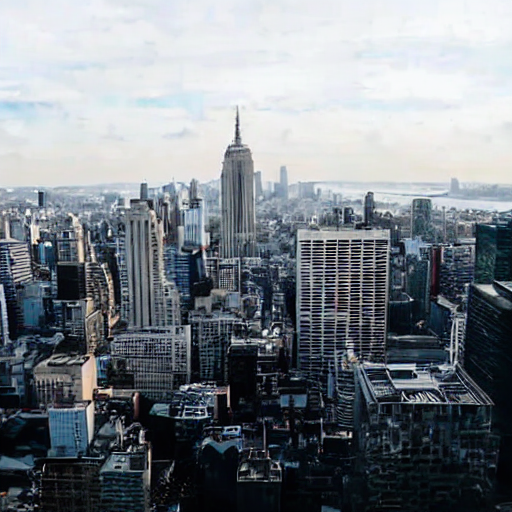

  0%|          | 0/21 [00:00<?, ?it/s]

strength=0.7


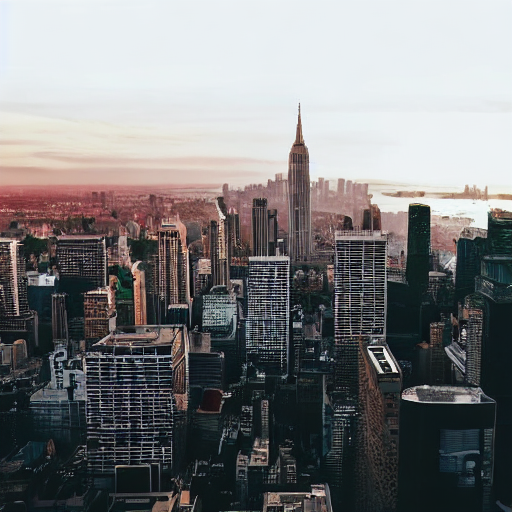

  0%|          | 0/30 [00:00<?, ?it/s]

strength=1.0


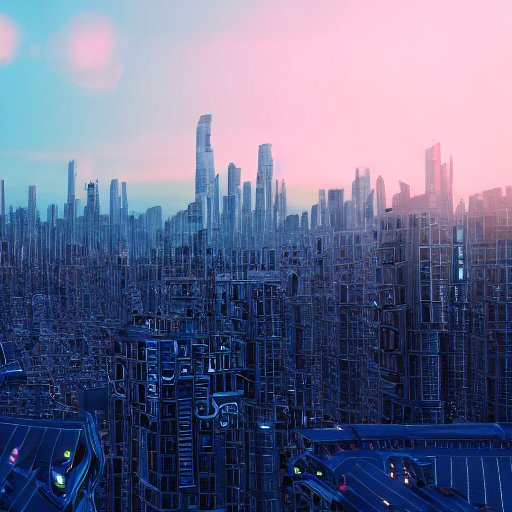

Done!


In [ ]:
from diffusers import AutoPipelineForImage2Image
from diffusers.utils import load_image
import torch
import gc
import os
from IPython.display import display


strengths = [0.2, 0.7, 1.0]
os.makedirs("outputs", exist_ok=True)

for strength in strengths:

    result = pipe(
        prompt="a photorealistic futuristic city skyline at sunset, cinematic lighting",
        image=init_image,
        strength=strength,
        guidance_scale=7.5,
        num_inference_steps=30
    ).images[0]

    print(f"strength={strength}")
    display(result)

    # Release temporary tensors between generations
    del result
    gc.collect()
    torch.cuda.empty_cache()

print("Done!")

### Output explanation
- At `strength=0.2–0.3`: you'll see the same composition, same layout, just cleaned-up textures/lighting — good for **style polishing**.
- At `strength=0.5–0.7`: silhouette and rough composition survive, but materials, colors, and fine detail change substantially — the "sweet spot" for most creative edits.
- At `strength=0.9+`: the output starts to look like a fresh text-to-image generation that vaguely echoes the input's composition.

**Common learner mistake:** setting `strength=1.0` and being confused why the input image seems ignored — at that point you've essentially replaced it with pure noise before denoising.

Img2img changes the **whole image at once**, proportionally to `strength`. That's fine when you want a global restyle — but what happens when you only want to fix one broken hand in an otherwise perfect portrait, and leave every other pixel untouched? `strength` alone can't do that, because it has no notion of "region." That gap is exactly what the next section solves.


---
## Section 2 — Inpainting and Outpainting

We just established that img2img treats the whole canvas equally. Now we solve the problem that raises: fixing **one region** (a broken hand, a logo, a missing object) while leaving everything else pixel-perfect.

### The analogy
Inpainting is like using masking tape before painting a wall — you tape off everything you want protected, and paint only shows up in the exposed area. The **mask** (a black-and-white image) tells the model: white = "regenerate this," black = "leave this untouched."

**Outpainting** is the same idea but the canvas is bigger than the original photo — you paste your original image onto a larger blank canvas, mark the new blank area as "white" (to be generated), and ask the model to imagine what continues naturally beyond the frame.


**Instructor note**:- Please upload a city image for the below code cell to work

**img link**:- https://drive.google.com/file/d/1cx1KsEwfuLMTsbaj6hQ6TUXvOSbK8Wsb/view?usp=sharing

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (79 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['structure of the glass']


  0%|          | 0/47 [00:00<?, ?it/s]

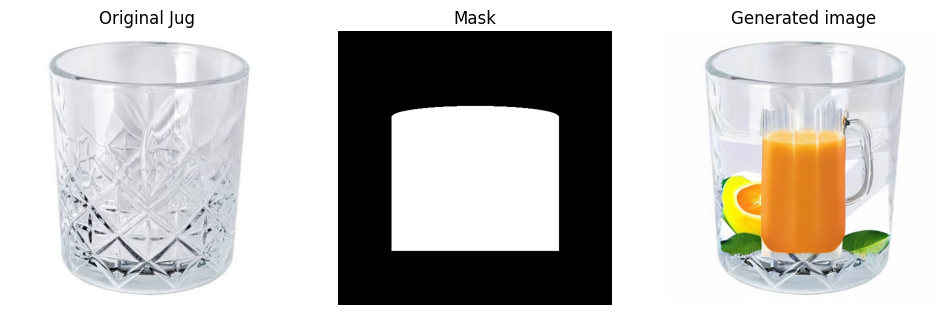

In [ ]:
from diffusers import AutoPipelineForInpainting
from diffusers.utils import load_image
from PIL import Image, ImageDraw
import torch
import matplotlib.pyplot as plt

# Reuse the already-loaded img2img pipeline
pipe = AutoPipelineForInpainting.from_pipe(pipe)

# Load the generated jug image
image = load_image(
    "/content/glass.jpeg"
).resize((512, 512))

# ---------------------------------------------------------
# MASK
# White = regenerate / add juice
# Black = preserve original image
# ---------------------------------------------------------

mask = Image.new("L", (512, 512), 0)
mask_draw = ImageDraw.Draw(mask)

# The jug body in the 512x512 image is approximately:
# x: 165 -> 405
# y: 130 -> 540
#
# We want the juice to fill most of the jug body,
# while keeping the upper empty portion visible.

# Main liquid region
mask_draw.rectangle(
    (100, 160, 412, 410),
    fill=255
)

# Slightly round/soften the top liquid boundary
mask_draw.ellipse(
    (100, 140, 412, 180),
    fill=255
)

# ---------------------------------------------------------
# INPAINT
# ---------------------------------------------------------

result = pipe(

    # Describe what you WANT the model to generate
    prompt=(
        "realistic vibrant orange mango juice completely filling the inside of the "
        "transparent plastic glass, bright saturated orange-yellow liquid, clearly "
        "visible liquid surface line near the top of the masked region, glossy "
        "reflections and light refraction through the transparent plastic, distinct "
        "color contrast between the liquid and the empty jug, believable high juice "
        "level, photorealistic, natural studio lighting, preserve the exact shape "
        "and structure of the glass"
    ),

    # Describe what you DON'T want the model to generate
    negative_prompt=(
        "empty jug, transparent water, colorless liquid, cloudy, blurry, "
        "distorted glass shape, low contrast, dull colors"
    ),

    # Original image that will be modified
    image=image,

    # Specifies the region that the model is allowed to modify
    # White/selected area → modify
    # Black/unselected area → preserve
    mask_image=mask,

    # Controls how strongly the original image is changed
    # Higher value → more freedom to change the masked region
    # Lower value → stay closer to the original image
    strength=0.95,

    # Controls how strongly the prompt influences the generated result
    # Higher value → follow the text prompt more strongly
    guidance_scale=9

# Extract the first generated image from the pipeline output
).images[0]

# ---------------------------------------------------------
# DISPLAY
# ---------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title("Original Jug")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Mask")
axes[1].axis("off")

axes[2].imshow(result)
axes[2].set_title("Generated image")
axes[2].axis("off")

plt.show()

### Code — Outpainting (canvas extension)

  0%|          | 0/30 [00:00<?, ?it/s]

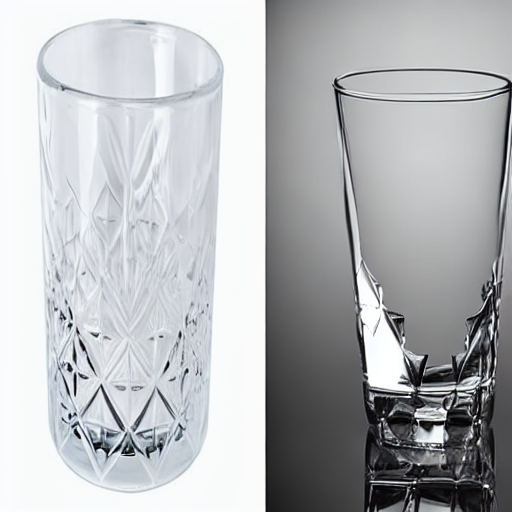

In [ ]:
from PIL import Image, ImageFilter

# --------------------------------------------------
# Use the same crystal glass image
# --------------------------------------------------

original = image.convert("RGB").resize((512, 512))

# Extend the canvas to the right
canvas_size = (
    original.width + 512,
    original.height
)

canvas = Image.new(
    "RGB",
    canvas_size,
    (255, 255, 255)   # white background matching the glass image
)

# Place the original glass image on the left
canvas.paste(
    original,
    (0, 0)
)


# --------------------------------------------------
# Create the outpainting mask
# Black  = preserve original image
# White  = generate new content
# --------------------------------------------------

mask = Image.new(
    "L",
    canvas_size,
    255
)

# Preserve the entire original glass image
mask.paste(
    0,
    (0, 0, original.width, original.height)
)


# --------------------------------------------------
# Generate the continuation
# --------------------------------------------------

result = pipe(
    prompt=(
        "seamless continuation of the existing crystal glass photograph, "
        "clean minimal white studio background, same soft lighting, same "
        "brightness, same perspective, same photographic style, subtle "
        "natural background shading, realistic studio photography, "
        "continuous empty space to the right of the glass, "
        "preserve the original glass completely unchanged"
    ),
    image=canvas,
    mask_image=mask,
    strength=1.0,
    guidance_scale=7,
    num_inference_steps=30
).images[0]

result

### Output explanation
- With inpainting, check the **seam** where the mask boundary sits — a well-tuned mask (slightly feathered edges, not a hard binary cutout) avoids visible edges. This is why most pipelines blur the mask slightly before use.
- With outpainting, the model uses the pixels near the boundary as context — the further from the known image, the more "creative freedom" it takes, which is why outpainting large areas in one step often drifts. **Iterative outpainting** (small extensions, repeated) gives more coherent results than one giant extension.

Notice what inpainting and img2img have in common: both only protect **pixels** — a mask or a strength value that operates on the raw image. Neither has any concept of "pose" or "3D layout." So if you want to keep an exact pose while completely changing the style, medium, or content (turn a photographed person into a 3D-rendered robot in the same stance), pixel-level masking can't express that constraint. We need to condition on **structure** instead — which is what ControlNet gives us next.


---
## Section 3 — ControlNet: Spatial Conditioning

### The analogy
Think of ControlNet as tracing paper laid over a photograph. The tracer doesn't care about the photo's colors or textures — only its **outline, pose, or depth**. ControlNet extracts that "tracing" (an edge map, a skeleton, a depth map) from a source image and forces the diffusion model to respect it at every denoising step, while text still controls everything else (style, color, mood).

Technically, ControlNet is a trainable copy of the U-Net's encoder blocks that takes the conditioning image (e.g., a Canny edge map) as an additional input and injects features into the frozen base model via "zero convolutions," so the base model's original capabilities are preserved while gaining a new spatial constraint.


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

There are modules in ControlNetModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/35 [00:00<?, ?it/s]

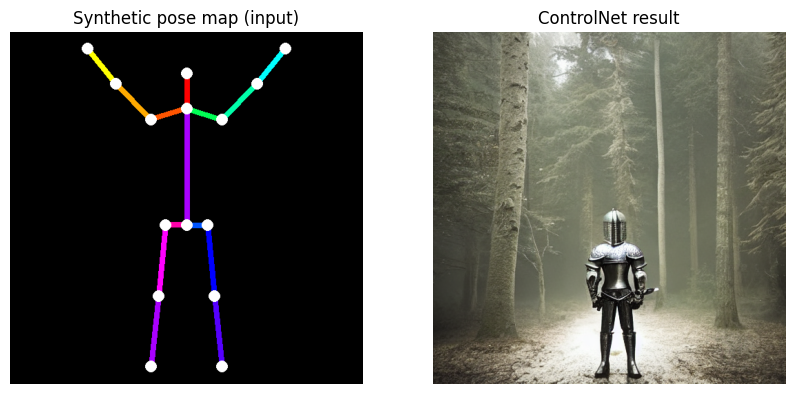

In [ ]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def make_synthetic_pose_map(size=512):
    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    draw = ImageDraw.Draw(canvas)

    kp = {
        "head":       (0.50, 0.12),
        "neck":       (0.50, 0.22),
        "r_shoulder": (0.40, 0.25), "r_elbow": (0.30, 0.15), "r_wrist": (0.22, 0.05),
        "l_shoulder": (0.60, 0.25), "l_elbow": (0.70, 0.15), "l_wrist": (0.78, 0.05),
        "hip":        (0.50, 0.55),
        "r_hip":      (0.44, 0.55), "r_knee": (0.42, 0.75), "r_ankle": (0.40, 0.95),
        "l_hip":      (0.56, 0.55), "l_knee": (0.58, 0.75), "l_ankle": (0.60, 0.95),
    }
    kp = {k: (x * size, y * size) for k, (x, y) in kp.items()}

    bones = [
        ("head", "neck", (255, 0, 0)),
        ("neck", "r_shoulder", (255, 85, 0)), ("r_shoulder", "r_elbow", (255, 170, 0)), ("r_elbow", "r_wrist", (255, 255, 0)),
        ("neck", "l_shoulder", (0, 255, 85)), ("l_shoulder", "l_elbow", (0, 255, 170)), ("l_elbow", "l_wrist", (0, 255, 255)),
        ("neck", "hip", (170, 0, 255)),
        ("hip", "r_hip", (255, 0, 170)), ("r_hip", "r_knee", (255, 0, 255)), ("r_knee", "r_ankle", (170, 0, 255)),
        ("hip", "l_hip", (0, 85, 255)), ("l_hip", "l_knee", (0, 0, 255)), ("l_knee", "l_ankle", (85, 0, 255)),
    ]

    for a, b, color in bones:
        draw.line([kp[a], kp[b]], fill=color, width=8)
    for point in kp.values():
        x, y = point
        draw.ellipse((x - 8, y - 8, x + 8, y + 8), fill=(255, 255, 255))

    return canvas

pose_image = make_synthetic_pose_map()

# SD 1.5-compatible OpenPose ControlNet — move to cuda explicitly since it's new
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-openpose", torch_dtype=torch.float16
).to("cuda")

# Reuse the already-loaded SD 1.5 pipeline
pipe = StableDiffusionControlNetPipeline.from_pipe(pipe, controlnet=controlnet)

# Re-apply cpu offload so its hooks register the new controlnet component too
pipe.enable_model_cpu_offload()

result = pipe(
    prompt="a knight in ornate silver armor, standing in a misty forest, cinematic",
    image=pose_image,
    controlnet_conditioning_scale=0.8,
    num_inference_steps=35
).images[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pose_image); axes[0].set_title("Synthetic pose map (input)"); axes[0].axis("off")
axes[1].imshow(result); axes[1].set_title("ControlNet result"); axes[1].axis("off")
plt.show()

### Common ControlNet types (know these by name)

| Type | Extracts | Best for |
|---|---|---|
| OpenPose | Skeleton/joints | Human pose consistency |
| Canny | Edge map | Preserving object outlines |
| Depth (MiDaS) | Depth map | Preserving 3D layout/perspective |
| Segmentation | Region masks | Preserving object placement/category |
| Scribble/Lineart | Rough sketch | Sketch-to-image |

### Output explanation
- `controlnet_conditioning_scale` is your dial between "loosely inspired by structure" (0.3–0.5) and "must match structure exactly" (0.8–1.0).
- If output anatomy looks broken despite a clean pose map, check that the pose map resolution matches your output resolution — mismatches are the number one cause of "ControlNet isn't working" bugs.


---
## Section 4 — IP-Adapter: Image Prompting & Style Transfer

ControlNet solved structure — *where things are*. But structure was never the only thing designers struggle to describe in words. Try writing a text prompt that nails "that exact shade of teal and that painterly brushstroke style" — it's hard. Showing an example image is easy. IP-Adapter lets you do exactly that: prompt with an image instead of (or alongside) text.

### The analogy
If ControlNet is tracing paper (structure only), **IP-Adapter is a mood board** pinned next to the artist's easel. The artist glances at the mood board for color palette, texture, and "vibe," without literally copying its layout. Technically, IP-Adapter encodes a reference image with a CLIP image encoder and injects those embeddings into the cross-attention layers *alongside* your text embeddings — so image and text prompts co-drive generation.


In [ ]:
from diffusers import StableDiffusionPipeline
from PIL import Image, ImageDraw
import torch
import matplotlib.pyplot as plt

# Reuse the already-loaded SD 1.5 pipeline instead of a fresh SDXL download
pipe = StableDiffusionPipeline.from_pipe(pipe)

# Attention slicing (set in the very first cell) conflicts with IP-Adapter's own
# attention processors — disable it before loading the adapter
pipe.disable_attention_slicing()

# SD 1.5-compatible IP-Adapter weights (the SDXL ones won't match this UNet's cross-attention dims)
pipe.load_ip_adapter(
    "h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin"
)
pipe.set_ip_adapter_scale(0.6)   # balance between text prompt and image prompt

# Re-apply cpu offload so its hooks register the new adapter weights too
pipe.enable_model_cpu_offload()

# Build a synthetic "style reference" instead of loading an external file:
# a simple watercolor-ish gradient with soft blotches, to give IP-Adapter a color/texture mood to latch onto
def make_synthetic_style_reference(size=512):
    canvas = Image.new("RGB", (size, size), (245, 235, 220))
    draw = ImageDraw.Draw(canvas)
    blotches = [
        ((30, 40, 90), (60, 60), 180),
        ((200, 140, 60), (300, 120), 150),
        ((90, 150, 130), (150, 350), 160),
        ((180, 90, 120), (380, 300), 140),
    ]
    for color, (x, y), r in blotches:
        draw.ellipse((x - r, y - r, x + r, y + r), fill=color)
    return canvas.filter(__import__("PIL").ImageFilter.GaussianBlur(40))

style_reference = make_synthetic_style_reference()

result = pipe(
    prompt="a mountain village at dawn",
    ip_adapter_image=style_reference,
    num_inference_steps=30
).images[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(style_reference); axes[0].set_title("Synthetic style reference"); axes[0].axis("off")
axes[1].imshow(result); axes[1].set_title("IP-Adapter result"); axes[1].axis("off")
plt.show()

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


models/ip-adapter_sd15.bin: reconstructing file:   0%|          |  0.00B / 44.6MB            

models/ip-adapter_sd15.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

models/image_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.53GB            

models/image_encoder/model.safetensors: downloading bytes:           |  0.00B            

### Output explanation
- `ip_adapter_scale` near 0.3 → mostly text-driven, image is a light nudge.
- `ip_adapter_scale` near 0.8–1.0 → the output starts strongly mimicking the reference's colors/texture/composition, sometimes overriding your text prompt.
- IP-Adapter is the backbone of most "style transfer" and "character consistency across images" tools you'll see in production apps.

So far we've used ControlNet and IP-Adapter one at a time. But real production briefs rarely need just one constraint — a game studio might need "this exact character pose" **and** "this exact background depth layout" simultaneously. Since ControlNet already accepts a single conditioning map, the natural next question is: can we give it more than one at once?


---
## Section 5 — Multi-ControlNet for Complex Compositions

### The analogy
One ControlNet is one tracing sheet. Multi-ControlNet is stacking **multiple transparent sheets** on top of the same canvas — one for pose, one for depth — and the artist honors all of them together, weighted by how "opaque" each sheet is.


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

There are modules in MultiControlNetModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/30 [00:00<?, ?it/s]

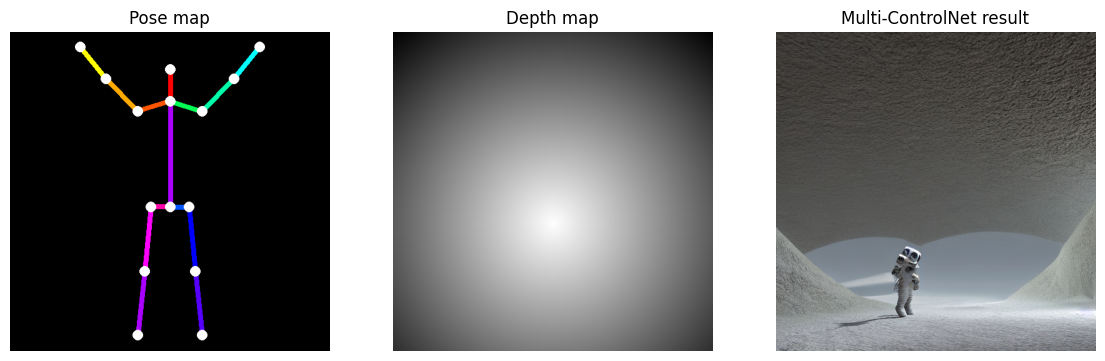

In [ ]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
from PIL import Image, ImageDraw
import torch
import matplotlib.pyplot as plt

# SD 1.5-compatible ControlNets (matching the already-loaded pipe's architecture)
controlnet_pose  = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-openpose", torch_dtype=torch.float16
).to("cuda")
controlnet_depth = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-depth", torch_dtype=torch.float16
).to("cuda")

# Reuse the already-loaded SD 1.5 pipeline instead of downloading a fresh SDXL pipeline
pipe = StableDiffusionControlNetPipeline.from_pipe(pipe, controlnet=[controlnet_pose, controlnet_depth])

# Re-apply cpu offload so its hooks register the new controlnet components
pipe.enable_model_cpu_offload()

# Build synthetic pose and depth maps instead of loading external files
def make_synthetic_pose_map(size=512):
    canvas = Image.new("RGB", (size, size), (0, 0, 0))
    draw = ImageDraw.Draw(canvas)
    kp = {
        "head":       (0.50, 0.12),
        "neck":       (0.50, 0.22),
        "r_shoulder": (0.40, 0.25), "r_elbow": (0.30, 0.15), "r_wrist": (0.22, 0.05),
        "l_shoulder": (0.60, 0.25), "l_elbow": (0.70, 0.15), "l_wrist": (0.78, 0.05),
        "hip":        (0.50, 0.55),
        "r_hip":      (0.44, 0.55), "r_knee": (0.42, 0.75), "r_ankle": (0.40, 0.95),
        "l_hip":      (0.56, 0.55), "l_knee": (0.58, 0.75), "l_ankle": (0.60, 0.95),
    }
    kp = {k: (x * size, y * size) for k, (x, y) in kp.items()}
    bones = [
        ("head", "neck", (255, 0, 0)),
        ("neck", "r_shoulder", (255, 85, 0)), ("r_shoulder", "r_elbow", (255, 170, 0)), ("r_elbow", "r_wrist", (255, 255, 0)),
        ("neck", "l_shoulder", (0, 255, 85)), ("l_shoulder", "l_elbow", (0, 255, 170)), ("l_elbow", "l_wrist", (0, 255, 255)),
        ("neck", "hip", (170, 0, 255)),
        ("hip", "r_hip", (255, 0, 170)), ("r_hip", "r_knee", (255, 0, 255)), ("r_knee", "r_ankle", (170, 0, 255)),
        ("hip", "l_hip", (0, 85, 255)), ("l_hip", "l_knee", (0, 0, 255)), ("l_knee", "l_ankle", (85, 0, 255)),
    ]
    for a, b, color in bones:
        draw.line([kp[a], kp[b]], fill=color, width=8)
    for point in kp.values():
        x, y = point
        draw.ellipse((x - 8, y - 8, x + 8, y + 8), fill=(255, 255, 255))
    return canvas

def make_synthetic_depth_map(size=512):
    # Simple radial gradient: bright center (near) fading to dark edges (far) —
    # loosely simulates a depth map where a central subject stands closer to camera
    canvas = Image.new("L", (size, size), 0)
    px = canvas.load()
    cx, cy = size / 2, size * 0.6
    max_dist = ((size / 2) ** 2 + (size * 0.6) ** 2) ** 0.5
    for x in range(size):
        for y in range(size):
            dist = ((x - cx) ** 2 + (y - cy) ** 2) ** 0.5
            val = int(255 * (1 - dist / max_dist))
            px[x, y] = max(0, val)
    return Image.merge("RGB", [canvas, canvas, canvas])

pose_map = make_synthetic_pose_map()
depth_map = make_synthetic_depth_map()

result = pipe(
    prompt="an astronaut exploring an alien cave, volumetric lighting",
    image=[pose_map, depth_map],
    controlnet_conditioning_scale=[0.7, 0.5],   # pose is prioritized over depth here
    num_inference_steps=30
).images[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(pose_map); axes[0].set_title("Pose map"); axes[0].axis("off")
axes[1].imshow(depth_map, cmap="gray"); axes[1].set_title("Depth map"); axes[1].axis("off")
axes[2].imshow(result); axes[2].set_title("Multi-ControlNet result"); axes[2].axis("off")
plt.show()

### Output explanation
When two conditioning maps disagree (e.g., the pose map implies a standing figure but the depth map implies a sitting one), the model averages/compromises — usually producing subtle artifacts. **Rule of thumb:** keep the sum of conditioning scales under roughly 1.3–1.5 for SDXL to avoid over-constraining and getting rigid, low-quality outputs.


### Quick Check — Quiz 3

**Question:** You want a generated image to strongly follow the color palette and brush texture of a reference painting, while letting the text prompt freely control the actual subject matter. Which tool and setting combination fits best?

- A) ControlNet with `controlnet_conditioning_scale=1.0`
- B) IP-Adapter with a low `ip_adapter_scale` around 0.2
- C) IP-Adapter with a high `ip_adapter_scale` around 0.8–1.0
- D) Img2img with `strength=0.1`

**Answer: C**

**Explanation:** IP-Adapter is designed to transfer style, color palette, and texture "vibe" from a reference image via CLIP image embeddings injected into cross-attention — exactly the goal described. A high scale (0.8–1.0) is needed because the request explicitly says "strongly follow" the palette and texture, and low scales (B) would only lightly nudge the output. ControlNet (A) conditions on structural layout (edges/pose/depth), not color or texture, so it's the wrong tool for this goal. Img2img at `strength=0.1` (D) would barely change a starting image and isn't built to transfer style from a separate reference image at all — it operates on one image, not two.


---
## Section 6 — Textual Inversion for Custom Concepts

Every technique so far reused concepts the base model already knew — poses, edges, styles it had already seen during training. ControlNet can trace *your* dog's pose, but it has no idea what makes your dog look like *your* dog rather than any other dog. To do that, we need the model to actually learn a brand-new concept it has never seen. That's a different family of techniques entirely — and Textual Inversion is the lightest one to start with.

### The analogy
The model already has a giant dictionary of "words" it understands (its token embedding space). Textual Inversion doesn't touch the model's brain at all — it just **invents one new word** (a token, e.g. `<my-dog>`) and finds the embedding vector for that word that best reproduces your 3–5 training images when used in a prompt. It's like teaching someone a new word by showing flashcards, without changing anything else about how they think.


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/50 [00:00<?, ?it/s]

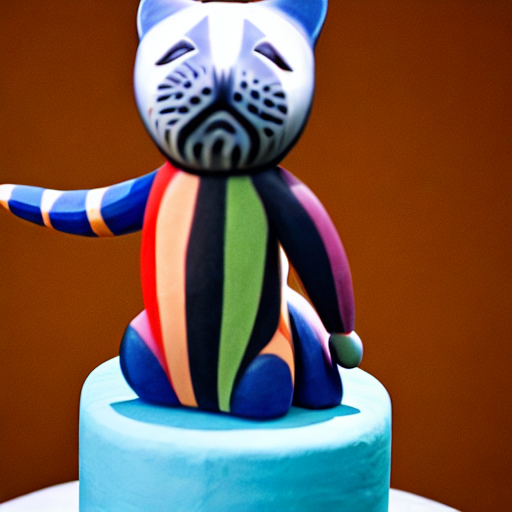

In [ ]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pipe(pipe)
pipe.enable_model_cpu_offload()

"""
accelerate launch textual_inversion.py \
  --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
  --train_data_dir="./my_dog_images" \
  --placeholder_token="<my-dog>" \
  --initializer_token="dog" \
  --resolution=512 \
  --train_batch_size=1 \
  --learning_rate=5e-4 \
  --max_train_steps=2000 \
  --output_dir="./ti_my_dog"
"""

# Only load the embedding if the token isn't already in the tokenizer —
# avoids the "already in vocabulary" error if this cell is re-run
if "<cat-toy>" not in pipe.tokenizer.get_vocab():
    pipe.load_textual_inversion("sd-concepts-library/cat-toy", token="<cat-toy>")

result = pipe(prompt="a photo of <cat-toy> sitting on a birthday cake, studio lighting").images[0]
result

### Output explanation
- Output file size: a few KB (just one embedding vector) — dramatically lighter than any other customization method here.
- Limitation: because we never touched model weights, textual inversion struggles with **significant pose/angle changes** of the subject — the "word" captures appearance well but not full 3D understanding of the subject.

That pose/angle limitation is the whole reason the next technique exists. If you need the model to genuinely understand your subject well enough to render it from new angles, in new outfits, under new lighting, a single embedding vector isn't expressive enough — you have to update the model's actual weights.


### Quick Check — Quiz 4

**Question:** Why does Textual Inversion struggle to render a learned subject from significantly new poses or angles compared to the training images?

- A) It requires at least 50 training images to generalize across poses, and most learners use only 3–5.
- B) It only learns a single embedding vector for a new token; the model's weights (its actual visual understanding) are never updated.
- C) It uses a corrupted initializer token by default, which limits pose diversity.
- D) The `guidance_scale` is hardcoded too low during Textual Inversion training.

**Answer: B**

**Explanation:** Textual Inversion optimizes only the embedding vector for one new placeholder token in the frozen model's existing token space — it never modifies the U-Net or text encoder weights. So the model gains a good "word" that reproduces the subject's appearance in familiar contexts, but it has no new understanding of the subject's 3D structure, since nothing about how the model actually processes and renders images was changed. A is wrong because the small dataset size (3–5 images) is a feature of the method's efficiency, not the root cause of the pose limitation — even with more images, the weights still wouldn't update. C and D describe mechanisms that aren't part of how Textual Inversion works.


---
## Section 7 — DreamBooth for Personalized Models

### The analogy
If Textual Inversion is flashcards, **DreamBooth is an apprenticeship**. You're not teaching a new word — you're having the model practice drawing your specific subject repeatedly until it's baked into its "hands" (its weights), not just its "vocabulary." To prevent it from forgetting the general concept of "dog" while overfitting to your one dog, DreamBooth uses **prior preservation** — mixing in generic "dog" images during training so the model doesn't collapse its whole understanding of dogs into your one dog.


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

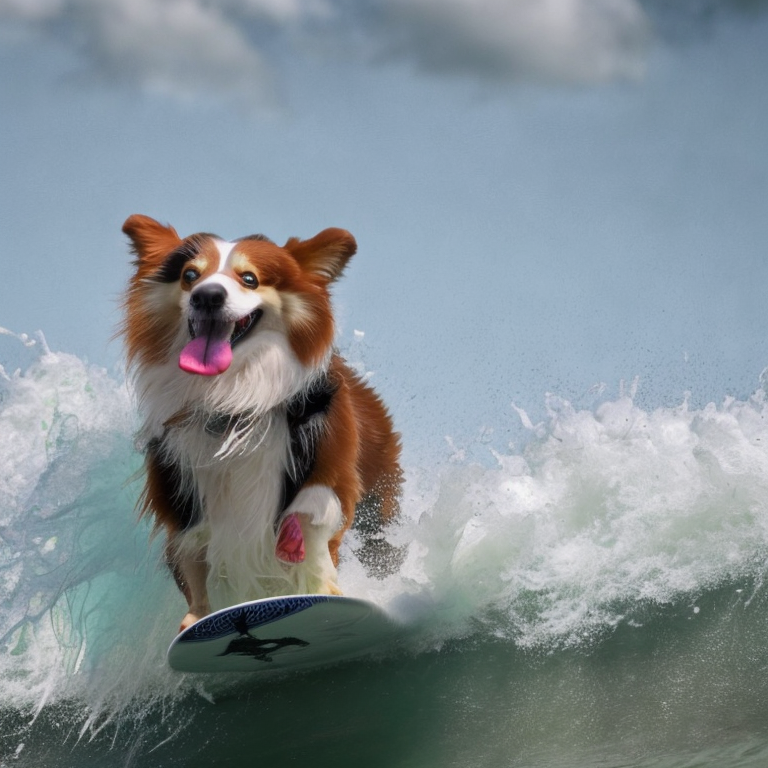

In [ ]:
from diffusers import StableDiffusionPipeline

# Training would normally look like this (commented out — it requires local
# instance images in ./my_dog_images and class images in ./class_dog_images,
# which this notebook doesn't have):
"""
accelerate launch train_dreambooth.py \
  --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
  --instance_data_dir="./my_dog_images" \
  --instance_prompt="a photo of sks dog" \
  --class_data_dir="./class_dog_images" \
  --class_prompt="a photo of a dog" \
  --with_prior_preservation --prior_loss_weight=1.0 \
  --resolution=512 \
  --train_batch_size=1 \
  --learning_rate=1e-6 \
  --max_train_steps=800 \
  --output_dir="./dreambooth_my_dog"
"""

# Inference: load a publicly available, already-trained DreamBooth checkpoint
# from the Hub instead, so we can demonstrate the technique without training locally.
# This is a full SD 1.5 checkpoint (not an adapter), so it's loaded fresh rather
# than reused via from_pipe() — DreamBooth produces an entirely new set of weights.
pipe = StableDiffusionPipeline.from_pretrained(
    "sd-dreambooth-library/dog-ppf-model", torch_dtype=torch.float16
).to("cuda")

result = pipe(prompt="a photo of sks dog surfing on a wave, dramatic lighting").images[0]
result

### Output explanation
- `sks` (or any rare token) is used as a unique identifier that isn't already loaded with meaning, so the model doesn't confuse it with existing concepts.
- Output: a full new checkpoint (2–7GB for SDXL) — heavy but capable of generalizing your subject across poses/lighting/contexts far better than Textual Inversion.
- Overfitting risk is real: too many steps and the model starts reproducing your exact training photos verbatim, losing prompt flexibility.

We now have two ends of a spectrum: Textual Inversion (cheap, limited) and DreamBooth/full fine-tuning (expensive, powerful, riskier). In practice, most working teams don't want either extreme — they want most of DreamBooth's expressiveness without its GPU bill or its full-checkpoint storage cost. That practical middle ground, LoRA, is what closes out this notebook.


---
## Section 8 — Decision Framework: LoRA vs Textual Inversion vs Full Fine-Tuning

### The analogy
- **Textual Inversion** = teaching someone a new *word*. Cheap, fast, but they still draw with the same hand.
- **LoRA** = giving someone a *specialized new muscle* for a specific skill, without retraining their whole body. You attach small trainable rank-decomposition matrices to the attention layers; the original weights stay frozen. It's dramatically cheaper than DreamBooth but far more expressive than Textual Inversion.
- **Full Fine-Tuning / DreamBooth** = full apprenticeship — retraining substantial parts of the "hand" itself. Most expressive, most expensive, highest overfitting/catastrophic-forgetting risk.

### Decision table

| Criterion | Textual Inversion | LoRA | Full Fine-tune / DreamBooth |
|---|---|---|---|
| Training data needed | 3–5 images | 10–30 images | 20–100+ images |
| Output size | ~KBs | ~10–200MB | 2–7GB (full checkpoint) |
| GPU memory needed | Low (~8GB) | Medium (~12–16GB) | High (~24GB+) |
| Can learn new poses/angles well | Weak | Good | Best |
| Risk of catastrophic forgetting | Very low | Low | Higher (needs prior preservation) |
| Combinable/stackable with other styles | Yes, easily | Yes, easily | Harder — it's a full model swap |
| Best for | Simple objects, faces, icons | Characters, art styles, product lines — the *industry default* today | Enterprise-scale brand models, when the LoRA quality ceiling isn't enough |


**The rule of thumb to walk away with:** *Start with LoRA by default.* Reach for Textual Inversion only when data/compute is extremely limited and pose flexibility doesn't matter. Reach for full fine-tuning only when you have real production scale — lots of data, a real GPU budget, and quality requirements LoRA can't hit.


### Quick Check — Quiz 5

**Question:** A small team has 15 well-lit photos of a product, a mid-range GPU (about 16GB VRAM), and needs the model to render the product convincingly from several new angles and settings. Based on the decision framework, what should they reach for first?

- A) Textual Inversion, because it trains fastest.
- B) LoRA, because it fits their data volume, GPU budget, and need for pose flexibility better than the alternatives.
- C) Full fine-tuning / DreamBooth, because it always gives the best possible quality regardless of resources.
- D) Multi-ControlNet, since the goal involves multiple camera angles.

**Answer: B**

**Explanation:** LoRA is built for exactly this middle case: it needs 10–30 images (the team has 15), fits in roughly 12–16GB of GPU memory (matching their mid-range GPU), and — unlike Textual Inversion — can learn new poses/angles well, since it actually updates attention-layer weights rather than only finding a token embedding. Textual Inversion (A) would train fast but is explicitly weak at pose/angle generalization, which is the team's core requirement. Full fine-tuning (C) would need more data (20–100+ images) and more GPU memory (24GB+) than the team has, and "always best regardless of resources" ignores the resource constraints the question specifies. Multi-ControlNet (D) is about conditioning generation on structural maps at inference time — it doesn't teach the model a new subject at all, so it doesn't solve the personalization problem here.


---
## Wrap-Up — What We Covered

- **Image-to-Image**: control how much of an existing image survives via `strength`.
- **Inpainting/Outpainting**: surgically regenerate specific regions or extend a canvas using masks.
- **ControlNet**: enforce structural conditioning (pose/depth/edges/segmentation) independent of style.
- **IP-Adapter**: prompt with an image instead of (or alongside) text, for style/identity transfer.
- **Multi-ControlNet**: stack multiple structural constraints simultaneously, balancing their weights.
- **Textual Inversion**: cheaply teach the model a new "word" for a concept without touching its weights.
- **DreamBooth**: deeply teach the model a new subject by updating weights, with prior preservation to avoid forgetting.
- **LoRA vs TI vs Full Fine-tune**: a practical, cost/quality-driven decision framework — LoRA is today's default.

Notice the thread running through all eight sections: each one exists because the previous tool hit a wall. Img2img couldn't protect specific regions → inpainting. Inpainting couldn't protect structure while changing everything else → ControlNet. ControlNet couldn't take style/mood from an image → IP-Adapter. A single ControlNet couldn't express two constraints at once → Multi-ControlNet. None of the above could teach the model something it had never seen → Textual Inversion. Textual Inversion couldn't generalize across pose → DreamBooth. And DreamBooth's cost/risk was too high for everyday use → LoRA, today's practical default.

### Bridge to the Next Notebook
Everything here was about giving *you*, the human, precise manual control over a single generation. But in real products, you often don't want to manually tune `strength` or `controlnet_conditioning_scale` for every image — you want a **system** that decides these things, checks its own output, and fixes mistakes automatically. Next, we hand these exact tools (img2img, inpainting, ControlNet, upscaling) over to an **LLM-driven agent** that plans, critiques, and iteratively refines images on its own — and we'll close with a full hands-on build of exactly that system.
